# 07 · Uplift: a quién contactar para cambiarle la decisión

**Sesión 7 · Uplift y causalidad** (ruta Paid Media, semana 7: modelo uplift con Hillstrom atado a un presupuesto; catálogo: S, T, X-learner).

El A/B (sesión 6) dio el efecto **promedio**. El uplift busca el efecto **de cada cliente** para contactar solo a los *persuadibles* y no gastar en los *seguros* (compran igual) ni en los *no molestar*.

| | Compra si NO lo contacto | Compra si lo contacto | ¿Contactar? |
|---|---|---|---|
| Persuadible | no | sí | **sí** |
| Seguro | sí | sí | no (gasto de más) |
| Causa perdida | no | no | no |
| No molestar | sí | no | **nunca** |

Hillstrom: cross-fitting de 5 pliegues (64.000 clientes). Lenta: prueba del 30% (687 mil). `python -m growth_lab.uplift` (unos minutos); este notebook lee los resultados guardados en `data/processed/upl_*`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from growth_lab import db

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
P = db.PROCESSED
qini = pd.read_parquet(P / "upl_qini.parquet")
met = pd.read_parquet(P / "upl_metricas.parquet")
pol = pd.read_parquet(P / "upl_politicas.parquet")

## 1. ¿Hay diferencias entre clientes que se puedan aprovechar? (Qini por cliente, IC 90%)

Qini > 0 con IC que no cruza 0 = el modelo concentra el efecto en los primeros que elige. *Propensión* es el contraste: ordena por quién compra más, no por quién cambia.

In [2]:
met["senal"] = (met.qini_p05 > 0).map({True: "sí", False: "no"})
met.pivot_table(index=["datos", "resultado"], columns="modelo", values="qini").round(4)

modelo                                  propension  resultado_transformado  \
datos                     resultado                                          
hillstrom · Mens E-Mail   spend             0.0214                  0.0280   
                          visit             0.0028                 -0.0006   
hillstrom · Womens E-Mail spend             0.0161                  0.0160   
                          visit             0.0044                  0.0053   
lenta                     response_att      0.0006                 -0.0001   

modelo                                  s_learner  t_learner  x_learner  
datos                     resultado                                      
hillstrom · Mens E-Mail   spend            0.0130     0.0413    -0.0034  
                          visit            0.0000    -0.0003    -0.0008  
hillstrom · Womens E-Mail spend            0.0308    -0.0124     0.0086  
                          visit            0.0072     0.0061     0.0062  
lenta                     response_att     0.0004     0.0004     0.0011

In [3]:
met[["datos", "resultado", "modelo", "qini", "qini_p05", "qini_p95", "senal"]].round(4)

,datos,resultado,modelo,qini,qini_p05,qini_p95,senal
0,hillstrom · Mens E-Mail,spend,s_learner,0.0130,-0.0529,0.0801,no
1,hillstrom · Mens E-Mail,spend,t_learner,0.0413,-0.0258,0.1137,no
2,hillstrom · Mens E-Mail,spend,x_learner,-0.0034,-0.0686,0.0748,no
3,hillstrom · Mens E-Mail,spend,resultado_transformado,0.0280,-0.0430,0.1038,no
4,hillstrom · Mens E-Mail,spend,propension,0.0214,-0.0383,0.0842,no
5,hillstrom · Mens E-Mail,visit,s_learner,0.0000,-0.0018,0.0017,no
6,hillstrom · Mens E-Mail,visit,t_learner,-0.0003,-0.0020,0.0014,no
7,hillstrom · Mens E-Mail,visit,x_learner,-0.0008,-0.0025,0.0009,no
8,hillstrom · Mens E-Mail,visit,resultado_transformado,-0.0006,-0.0021,0.0011,no
9,hillstrom · Mens E-Mail,visit,propension,0.0028,0.0014,0.0044,sí


## 2. Curvas Qini donde sí hay señal

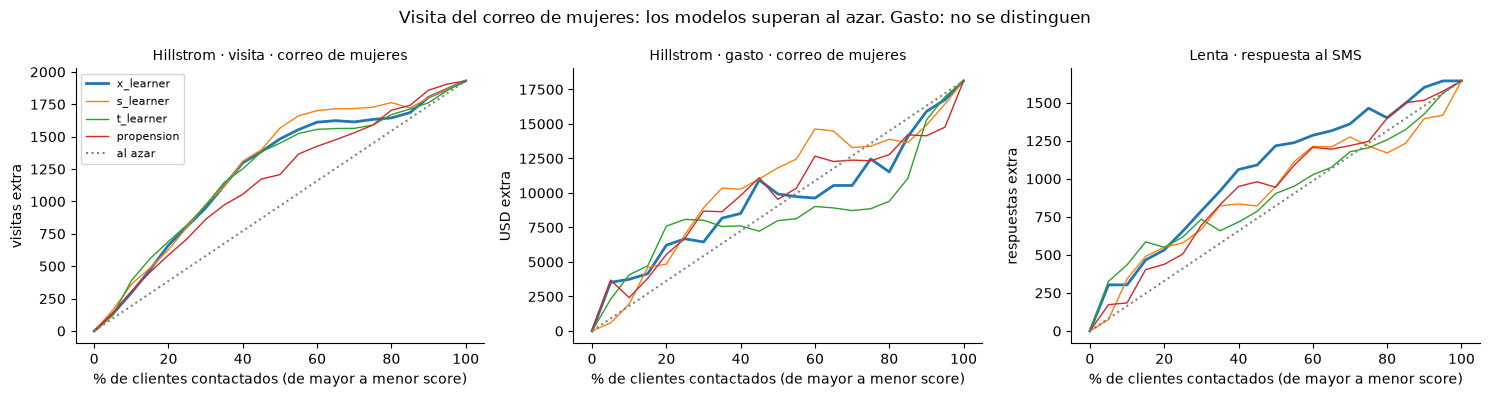

In [4]:
casos = [("hillstrom · Womens E-Mail", "visit", "Hillstrom · visita · correo de mujeres", "visitas extra"),
         ("hillstrom · Womens E-Mail", "spend", "Hillstrom · gasto · correo de mujeres", "USD extra"),
         ("lenta", "response_att", "Lenta · respuesta al SMS", "respuestas extra")]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for a, (datos, res, titulo, unidad) in zip(axs, casos):
    q = qini[(qini.datos == datos) & (qini.resultado == res)]
    for m in ["x_learner", "s_learner", "t_learner", "propension"]:
        g = q[q.modelo == m]
        a.plot(g.fraccion * 100, g.ganancia, label=m, lw=2 if m == "x_learner" else 1)
    total = q.ganancia.iloc[-1] if len(q) else 0
    a.plot([0, 100], [0, q[q.fraccion == 1].ganancia.mean()], color="grey", ls=":", label="al azar")
    a.set_title(titulo, fontsize=10); a.set_xlabel("% de clientes contactados (de mayor a menor score)"); a.set_ylabel(unidad)
axs[0].legend(fontsize=8)
fig.suptitle("Visita del correo de mujeres: los modelos superan al azar. Gasto: no se distinguen")
fig.tight_layout(); fig.savefig("../docs/img/uplift_qini.png", dpi=150); plt.show()

## 3. ¿Conviene personalizar el envío? (valor de cada política con IPW, 64.000 clientes)

IPW: como el sorteo fue 1/3 por brazo, el valor de una política se estima con los clientes a los que, por azar, les tocó lo que la política habría elegido, repesados por 3.

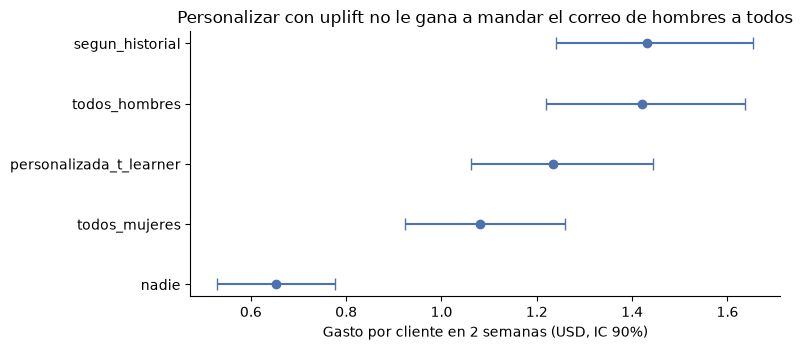

,politica,valor_por_cliente,incremental_vs_nadie,inc_ic_inf,inc_ic_sup,vs_todos_hombres,vs_h_ic_inf,vs_h_ic_sup,pct_con_correo,pct_hombres,margen_neto_por_cliente
0,nadie,0.652,0.000,0.000,0.000,-0.769,-1.000,-0.536,0.000,0.000,0.196
1,todos_hombres,1.421,0.769,0.536,1.000,0.000,0.000,0.000,1.000,1.000,0.416
2,todos_mujeres,1.080,0.428,0.225,0.657,-0.341,-0.596,-0.068,1.000,0.000,0.314
3,segun_historial,1.432,0.780,0.542,1.016,0.011,-0.142,0.175,1.000,0.551,0.420
4,personalizada_t_learner,1.234,0.582,0.391,0.807,-0.186,-0.377,0.030,0.805,0.462,0.362


In [5]:
orden = ["nadie", "todos_mujeres", "personalizada_t_learner", "todos_hombres", "segun_historial"]
p = pol.set_index("politica").loc[orden]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.errorbar(p.valor_por_cliente, range(len(p)), xerr=[p.valor_por_cliente - p.ic_inf, p.ic_sup - p.valor_por_cliente],
            fmt="o", capsize=4, color="#4C72B0")
ax.set_yticks(range(len(p)), p.index); ax.set_xlabel("Gasto por cliente en 2 semanas (USD, IC 90%)")
ax.set_title("Personalizar con uplift no le gana a mandar el correo de hombres a todos")
fig.tight_layout(); fig.savefig("../docs/img/uplift_politicas.png", dpi=150); plt.show()
pol[["politica", "valor_por_cliente", "incremental_vs_nadie", "inc_ic_inf", "inc_ic_sup", "vs_todos_hombres", "vs_h_ic_inf", "vs_h_ic_sup", "pct_con_correo", "pct_hombres", "margen_neto_por_cliente"]].round(3)

## 4. Presupuesto parcial: Lenta con el X-learner

Si solo alcanza para contactar a una parte, ¿cuánto de la respuesta extra se consigue?

In [6]:
q = qini[(qini.datos == "lenta") & (qini.modelo == "x_learner")].copy()
total = q.ganancia.iloc[-1]
q["al_azar"] = q.fraccion * total
q["veces_el_azar"] = q.ganancia / q.al_azar
q[q.fraccion.isin([0.1, 0.2, 0.3, 0.5, 0.7, 1.0])][["fraccion", "ganancia", "al_azar", "veces_el_azar"]].round(2)

,fraccion,ganancia,al_azar,veces_el_azar
464,0.1,303.11,164.41,1.84
466,0.2,532.31,328.82,1.62
468,0.3,789.23,493.23,1.60
472,0.5,1217.40,822.05,1.48
476,0.7,1360.70,1150.87,1.18
482,1.0,1644.10,1644.10,1.00


## Mis conclusiones (Neider)

1. **Mando el correo de hombres a todos.** Personalizar con uplift dio 1,23 USD por cliente frente a 1,42 de la regla simple: con el gasto, los modelos solo ven ruido.
2. **El uplift sirve donde hay diferencias reales entre clientes:** en la visita del correo de mujeres todos los modelos le ganan al azar y a la propensión. Ahí sí hay persuadibles que encontrar.
3. **Propensión no es uplift:** ordenar por quién compra más elige a los "seguros". En el correo de mujeres el uplift le ganó a la propensión (0,0072 contra 0,0044).
4. **El X-learner es mi modelo de referencia:** fue el único con señal en Lenta, donde el grupo de control es la cuarta parte; con el 30% del presupuesto consigue 1,6 veces lo que el azar.
5. **Mi regla:** antes de personalizar, mido si hay diferencias entre clientes con el Qini y su intervalo. Si no las hay, decido con el efecto promedio del A/B.
6. **Para la retención (Complete Journey)** no puedo entrenar uplift porque las campañas no fueron al azar. La sesión 8 estima su efecto corrigiendo la selección.